In [1]:
import os
import math
import matplotlib.pyplot as plt
import numpy as np 
import pandas as pd 
import seaborn as sns
from sklearn.linear_model import LinearRegression 
import scipy as sp 
import pylab as pl
from scipy.optimize.minpack import curve_fit
from scipy.signal import savgol_filter
from copy import deepcopy
import tkinter as tk
from tkinter import filedialog as fd
from matplotlib.lines import Line2D
from scipy.stats import ttest_ind

/var/folders/vn/x3b09qc53pn6v31__3y7shwh0000gn/T/ipykernel_45649/3480937576.py:10: DeprecationWarning: Please import `curve_fit` from the `scipy.optimize` namespace; the `scipy.optimize.minpack` namespace is deprecated and will be removed in SciPy 2.0.0.
  from scipy.optimize.minpack import curve_fit


In [2]:
%matplotlib widget

## Reading in of data and plotting of the DIRK traces

In [4]:

myFile = pd.read_csv('/Users/theklavonbismarck/Downloads/MSdata_RL3.csv',header = 0, index_col=None) ## Insert path to data

myData = pd.DataFrame(columns = [])


condition_Con = myFile['Condition?']== 'Con'
dataCon = myFile[condition_Con].reset_index(drop = False)
print(dataCon)

condition_Drought = myFile['Condition?']== 'Dr'
dataDrought = myFile[condition_Drought].reset_index(drop = False)
print(dataDrought)


     index       ID                           Series  Repeat Condition?  Rep?  \
0        0  2926699                          W - Con       1        Con    10   
1        1  2926670                          W - Con       1        Con     1   
2        2  2926669                          W - Con       1        Con     2   
3        3  2926665                          W - Con       1        Con     4   
4        4  2926540                          W - Con       1        Con    10   
..     ...      ...                              ...     ...        ...   ...   
503    503  2901984  L12 - Con - 5, 7, 8, 10, 11, 12       1        Con     5   
504    504  2901921  L12 - Con - 5, 7, 8, 10, 11, 12       1        Con     8   
505    505  2901906  L12 - Con - 5, 7, 8, 10, 11, 12       1        Con    11   
506    506  2901905  L12 - Con - 5, 7, 8, 10, 11, 12       1        Con    10   
507    507  2901863  L12 - Con - 5, 7, 8, 10, 11, 12       1        Con    12   

    Which plant?  air_temp_

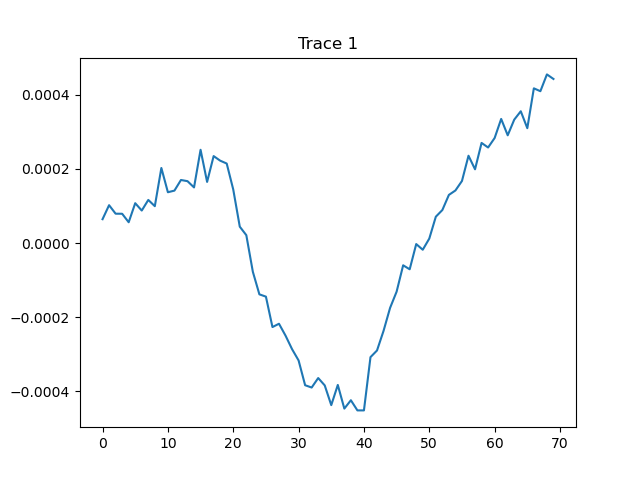

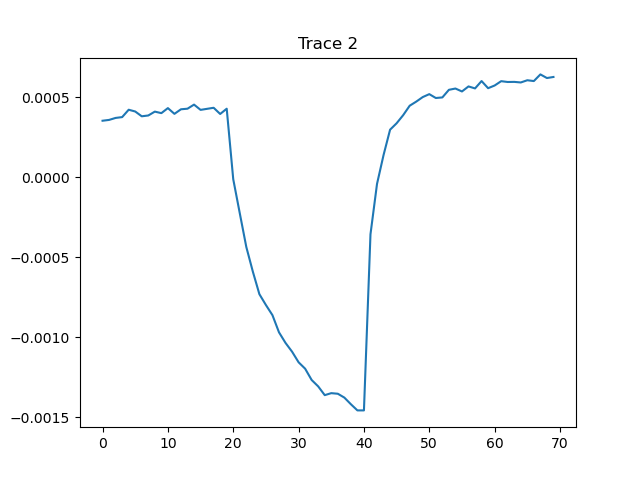

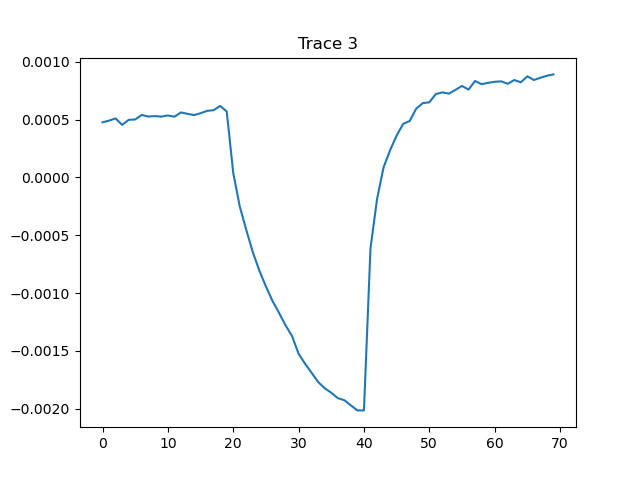

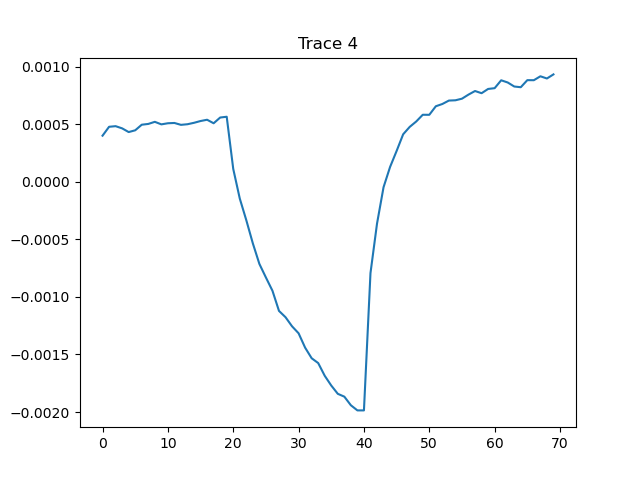

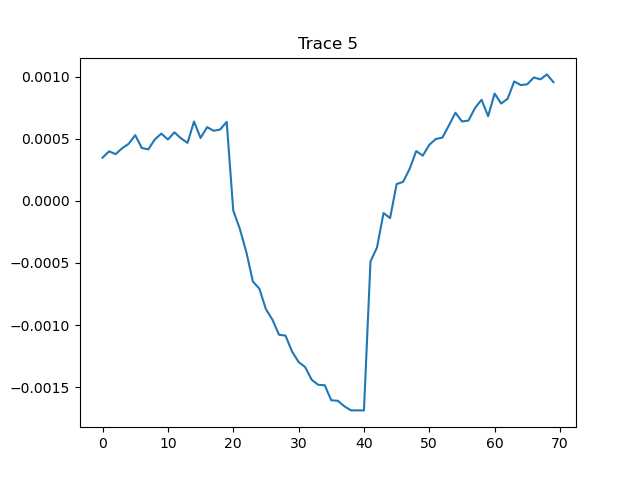

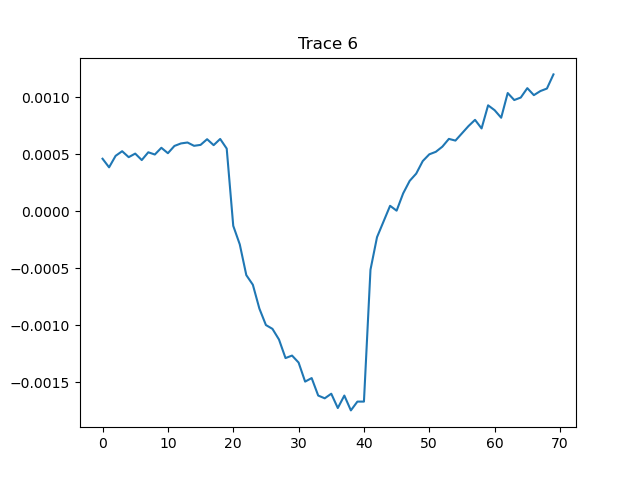

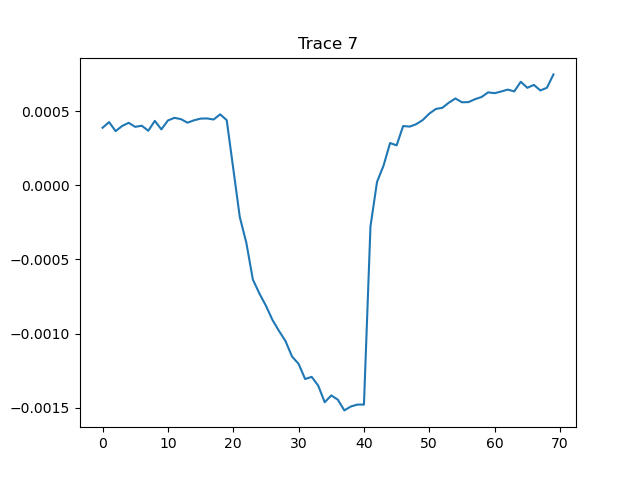

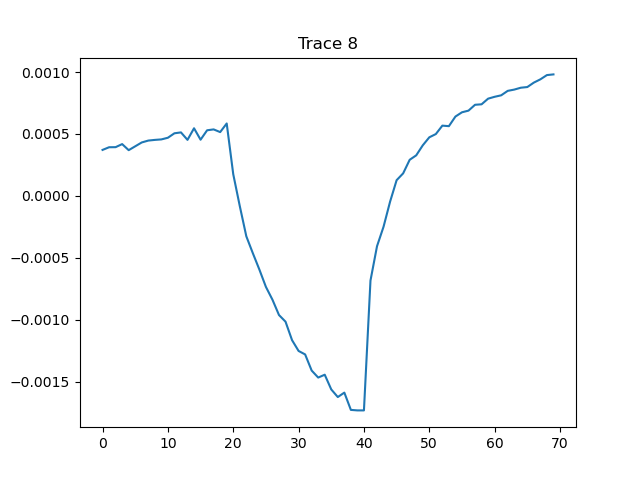

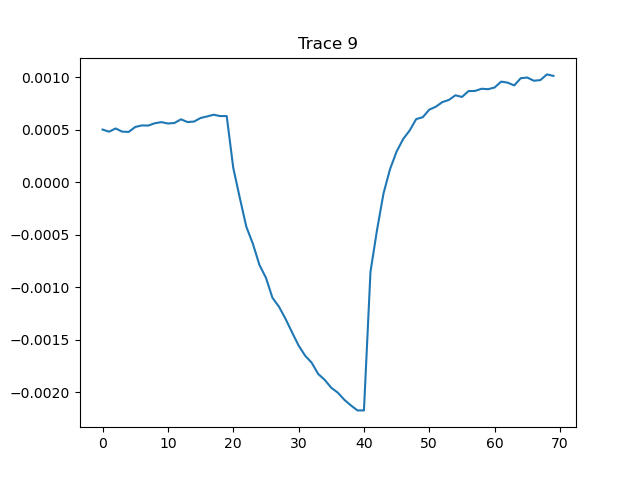

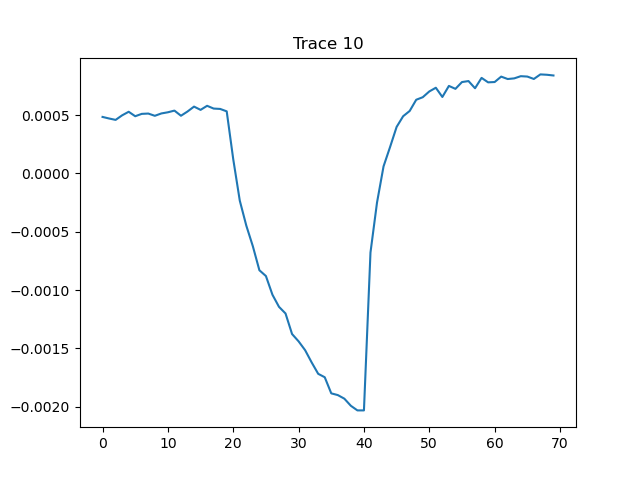

In [5]:
for i in range(min(10, len(myFile['ECS_averaged_trace']))):
    myString = myFile.iloc[i]['ECS_averaged_trace']
    my_list = myString.split(",")
    ECS520data = [float(x) for x in my_list]
    plt.figure()
    plt.plot(ECS520data)
    plt.title(f'Trace {i+1}')
    plt.show()


## Re-fitting of the DIRK data

In [6]:
#tdata = np.empty(50)
#b = np.arange(0, 105, 1.5)
#ind = np.arange(len(tdata))
#np.put(tdata, ind, b)
#print(tdata)

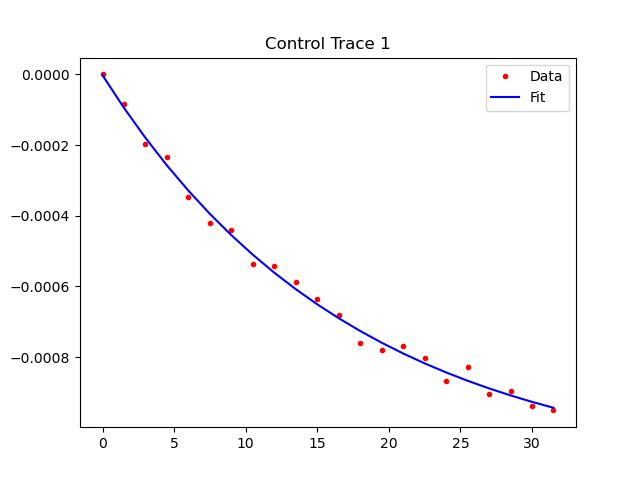

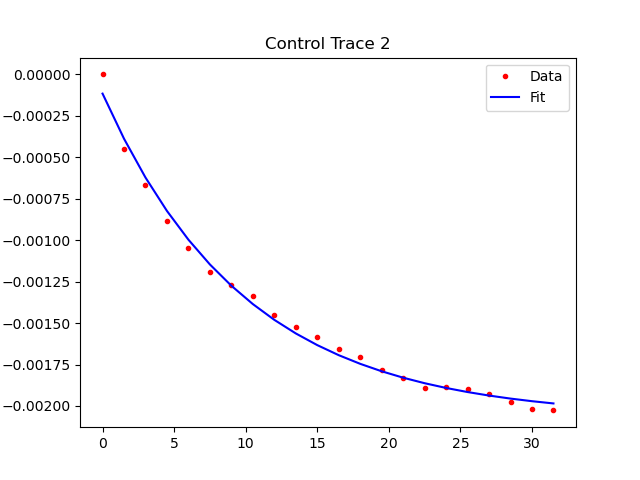

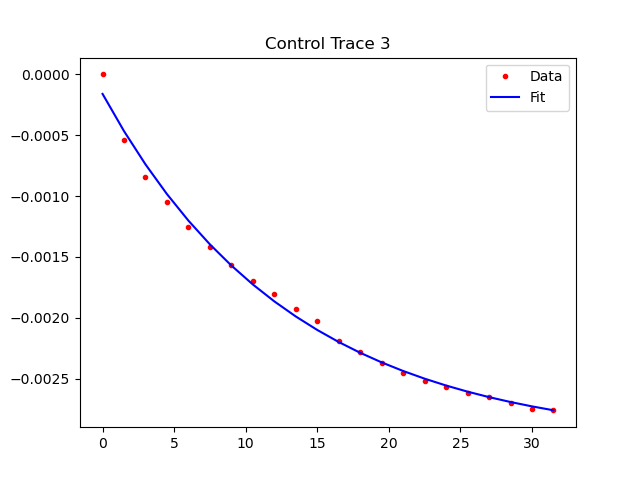

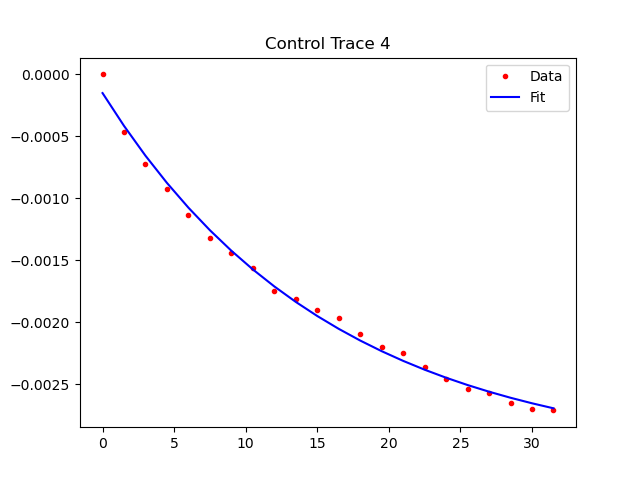

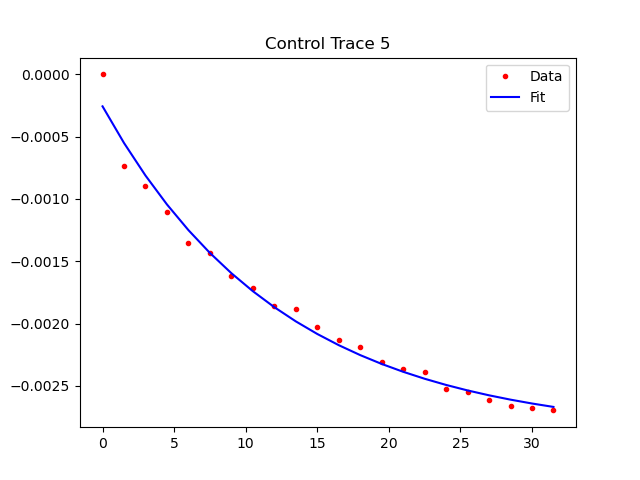

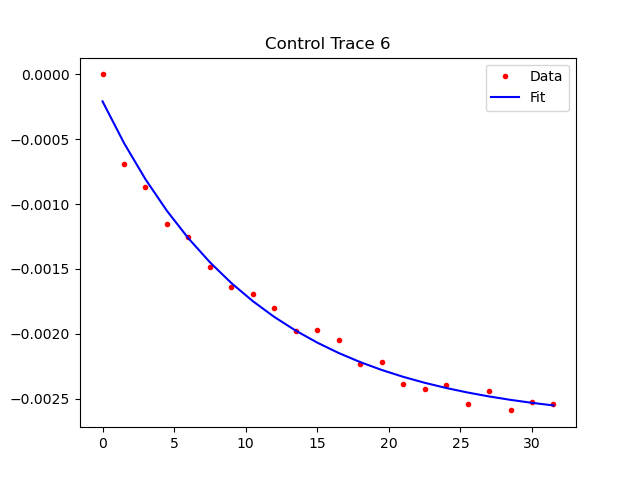

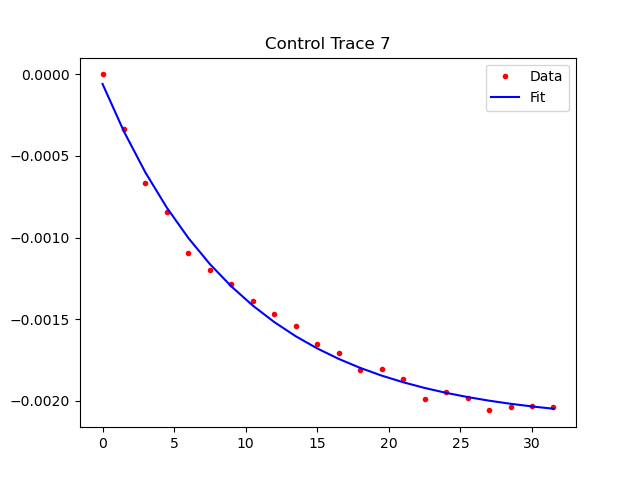

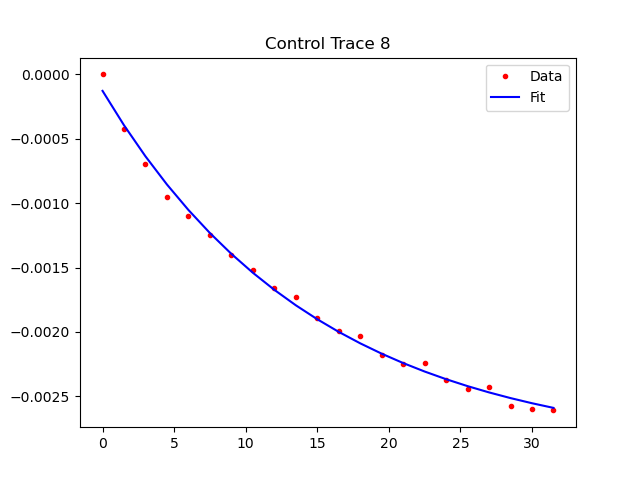

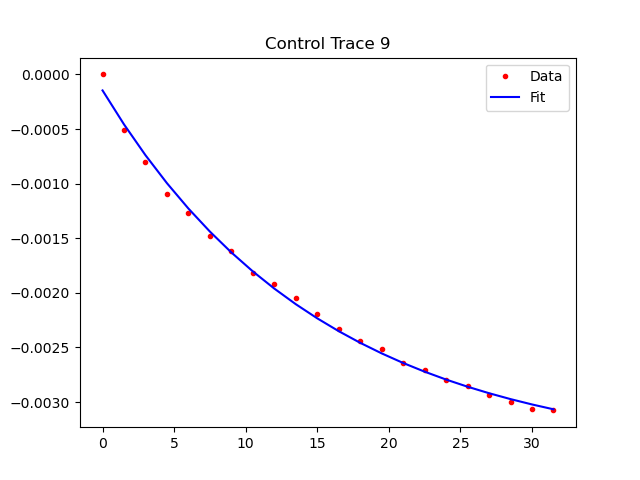

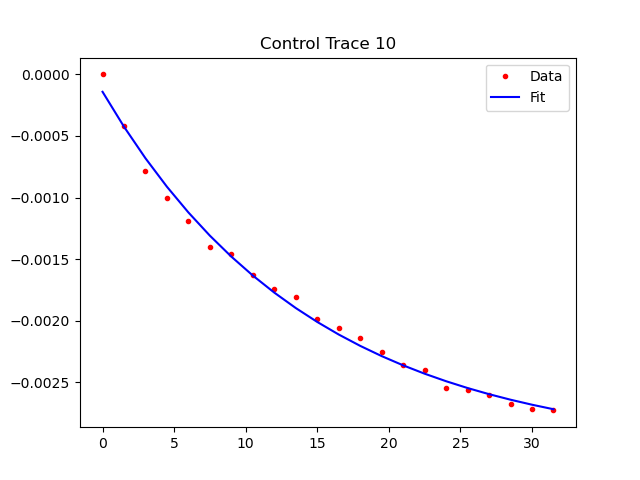

fail 0 302 could not convert string to float: '-6.854939230963113e-'


/var/folders/vn/x3b09qc53pn6v31__3y7shwh0000gn/T/ipykernel_45649/601090960.py:39: OptimizeWarning: Covariance of the parameters could not be estimated
  popt4, pcov4 = curve_fit(func4, tdata_fit, fitdata)
/var/folders/vn/x3b09qc53pn6v31__3y7shwh0000gn/T/ipykernel_45649/601090960.py:39: OptimizeWarning: Covariance of the parameters could not be estimated
  popt4, pcov4 = curve_fit(func4, tdata_fit, fitdata)
/var/folders/vn/x3b09qc53pn6v31__3y7shwh0000gn/T/ipykernel_45649/601090960.py:39: OptimizeWarning: Covariance of the parameters could not be estimated
  popt4, pcov4 = curve_fit(func4, tdata_fit, fitdata)
/var/folders/vn/x3b09qc53pn6v31__3y7shwh0000gn/T/ipykernel_45649/601090960.py:39: OptimizeWarning: Covariance of the parameters could not be estimated
  popt4, pcov4 = curve_fit(func4, tdata_fit, fitdata)
/var/folders/vn/x3b09qc53pn6v31__3y7shwh0000gn/T/ipykernel_45649/601090960.py:6: RuntimeWarning: overflow encountered in exp
  return a * np.exp(-t / tau) + c
/var/folders/vn/x3b09

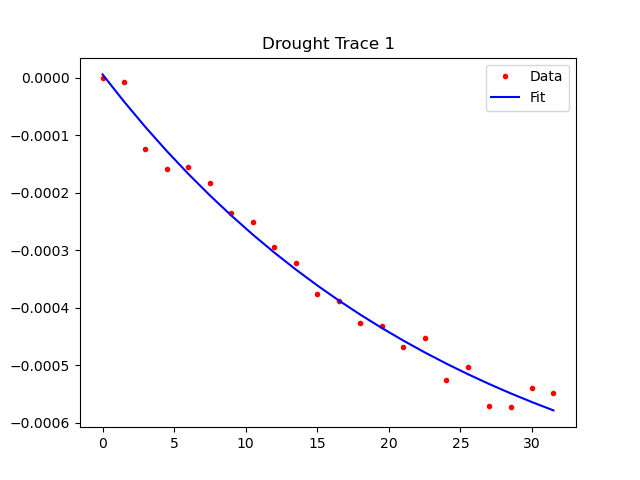

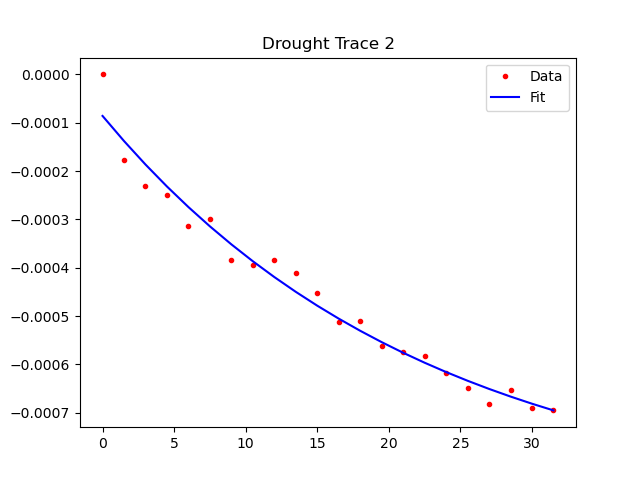

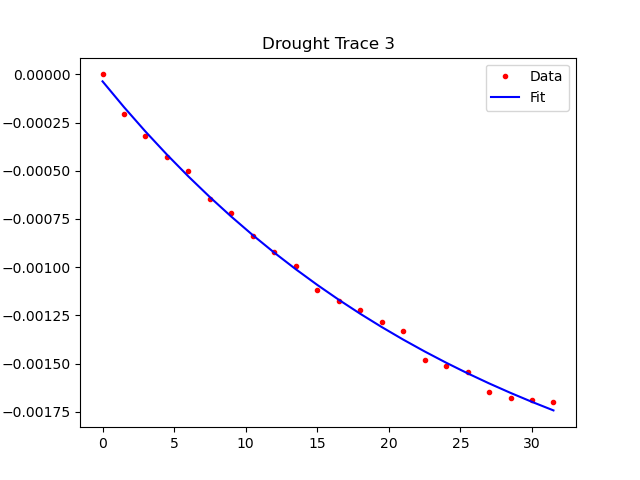

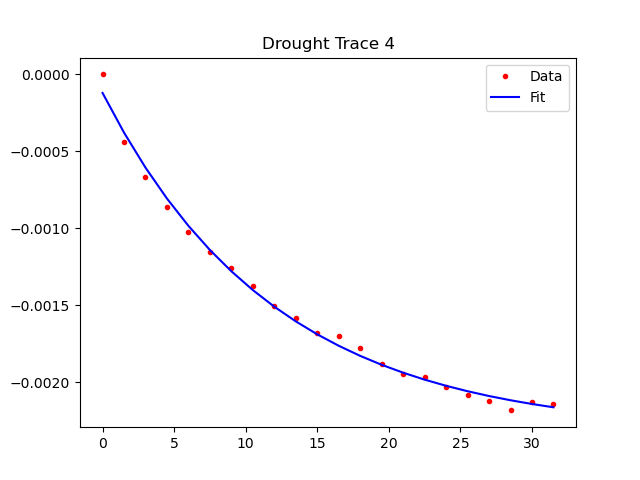

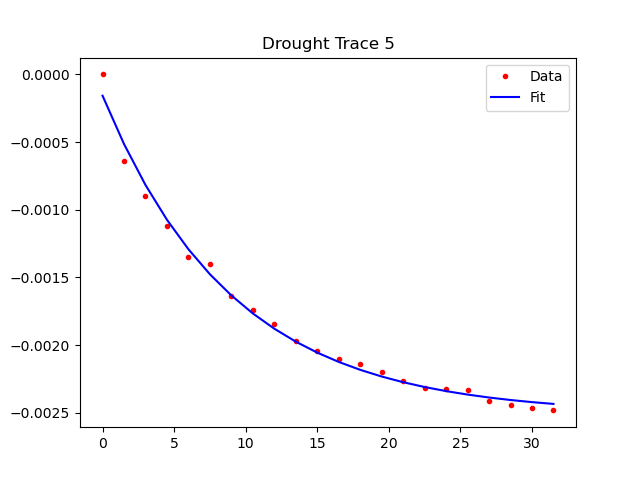

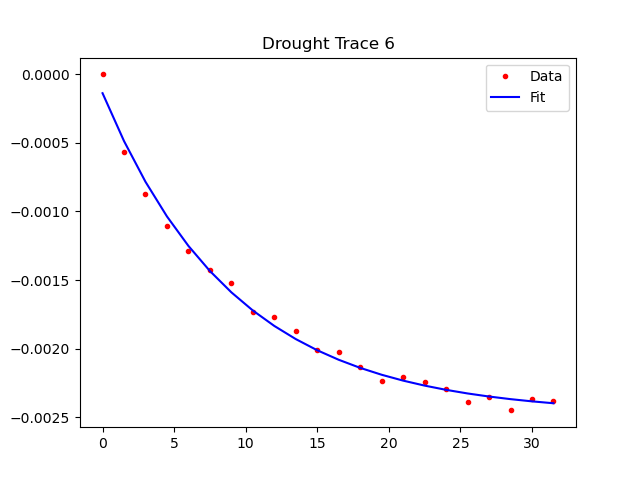

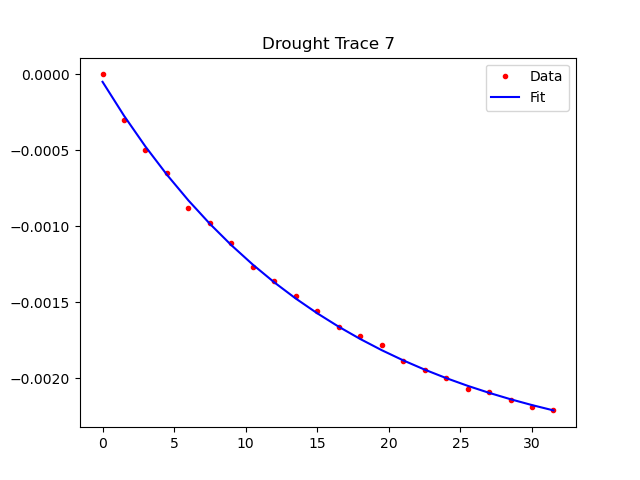

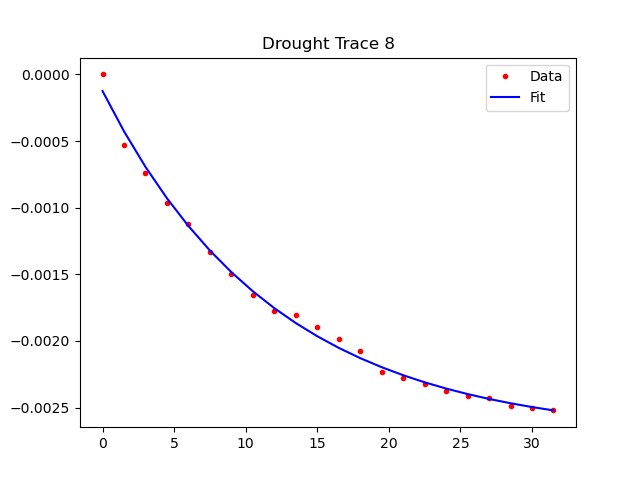

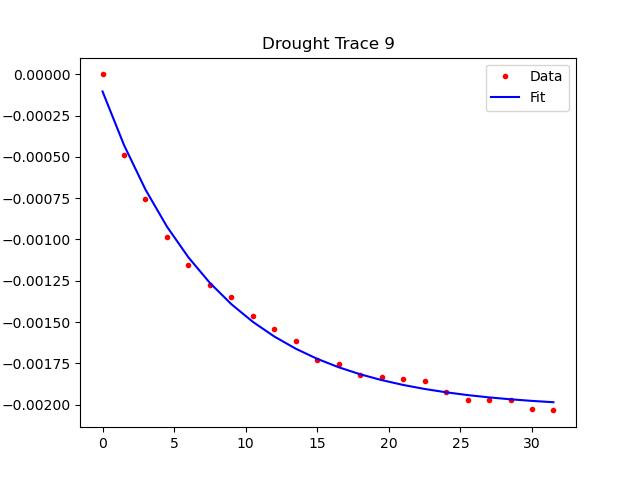

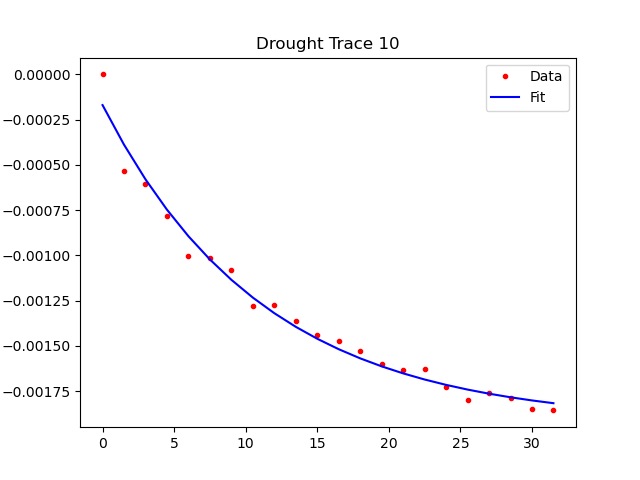

fail 1 100 could not convert string to float: '3.756883850188768e-'
fail 1 106 could not convert string to float: ''
fail 1 319 could not convert string to float: '-9.489897673309661e-'


/var/folders/vn/x3b09qc53pn6v31__3y7shwh0000gn/T/ipykernel_45649/601090960.py:39: OptimizeWarning: Covariance of the parameters could not be estimated
  popt4, pcov4 = curve_fit(func4, tdata_fit, fitdata)
/var/folders/vn/x3b09qc53pn6v31__3y7shwh0000gn/T/ipykernel_45649/601090960.py:6: RuntimeWarning: overflow encountered in exp
  return a * np.exp(-t / tau) + c
/var/folders/vn/x3b09qc53pn6v31__3y7shwh0000gn/T/ipykernel_45649/601090960.py:39: OptimizeWarning: Covariance of the parameters could not be estimated
  popt4, pcov4 = curve_fit(func4, tdata_fit, fitdata)
/var/folders/vn/x3b09qc53pn6v31__3y7shwh0000gn/T/ipykernel_45649/601090960.py:6: RuntimeWarning: overflow encountered in exp
  return a * np.exp(-t / tau) + c
/var/folders/vn/x3b09qc53pn6v31__3y7shwh0000gn/T/ipykernel_45649/601090960.py:39: OptimizeWarning: Covariance of the parameters could not be estimated
  popt4, pcov4 = curve_fit(func4, tdata_fit, fitdata)
/var/folders/vn/x3b09qc53pn6v31__3y7shwh0000gn/T/ipykernel_45649/60

In [7]:
worksheets = [dataCon, dataDrought]
MSdata_0 = pd.DataFrame()
MSdata_1 = pd.DataFrame()

def func4(t, a, tau, c):
    return a * np.exp(-t / tau) + c

for i in range(2):  # 0: control, 1: drought
    MSdata = worksheets[i].copy()
    plot_count = 0
    for x in range(len(MSdata)):
        try:
            ECS520data = MSdata.ECS_averaged_trace.apply(lambda x: x[1:-1].split(','))
            ECS520data = list(ECS520data)
            ECSdata = np.array(ECS520data[x], dtype=np.float32)

            tdata = np.empty(len(ECSdata))
            b = np.arange(0, 105, 1.5)
            ind = np.arange(len(tdata))
            np.put(tdata, ind, b)

            ytime = ECSdata[0:18]
            ytime = ytime.reshape(-1, 1)
            xtime = np.array(range(0, len(ytime))).reshape(-1, 1)
            linear_regressor = LinearRegression()
            linear_regressor.fit(xtime, ytime)
            slopebottom = linear_regressor.coef_[0][0]
            interbottom = linear_regressor.intercept_[0]
            baseline = (tdata * slopebottom) + interbottom
            ECSdata = ECSdata - baseline
            ECSdata = ECSdata - ECSdata[19]

            fitdata = ECSdata[19:41]
            tdata_fit = np.empty(len(fitdata))
            b_fit = np.arange(0, 105, 1.5)
            ind_fit = np.arange(len(tdata_fit))
            np.put(tdata_fit, ind_fit, b_fit)

            popt4, pcov4 = curve_fit(func4, tdata_fit, fitdata)
            a4, tau4, c4 = popt4
            y4_fit = func4(tdata_fit, a4, tau4, c4)

            # Only plot the first 10 fits for each group
            if plot_count < 10:
                plt.figure()
                plt.plot(tdata_fit, fitdata, 'r.', label='Data')
                plt.plot(tdata_fit, y4_fit, 'b', label='Fit')
                plt.title(f'{"Control" if i==0 else "Drought"} Trace {x+1}')
                plt.legend()
                plt.show()
                plot_count += 1

            MSdata.loc[x, 'gH+_refit'] = (1 / tau4) * 1000
            MSdata.loc[x, 'tau_refit'] = tau4
            MSdata.loc[x, 'ECSt_calc'] = a4

        except Exception as e:
            print('fail', i, x, e)
            MSdata.loc[x, 'gH+_refit'] = np.nan
            MSdata.loc[x, 'tau_refit'] = np.nan
            MSdata.loc[x, 'ECSt_calc'] = np.nan

    if i == 0:
        MSdata_0 = pd.concat([MSdata_0, MSdata], ignore_index=True)
    else:
        MSdata_1 = pd.concat([MSdata_1, MSdata], ignore_index=True)

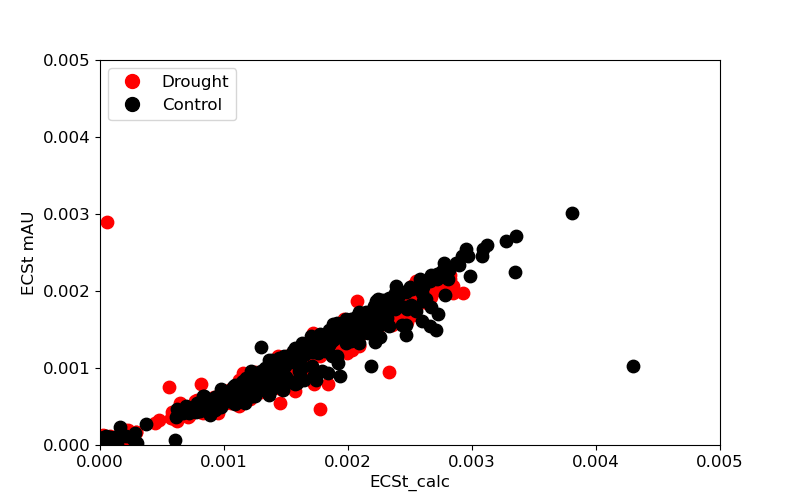

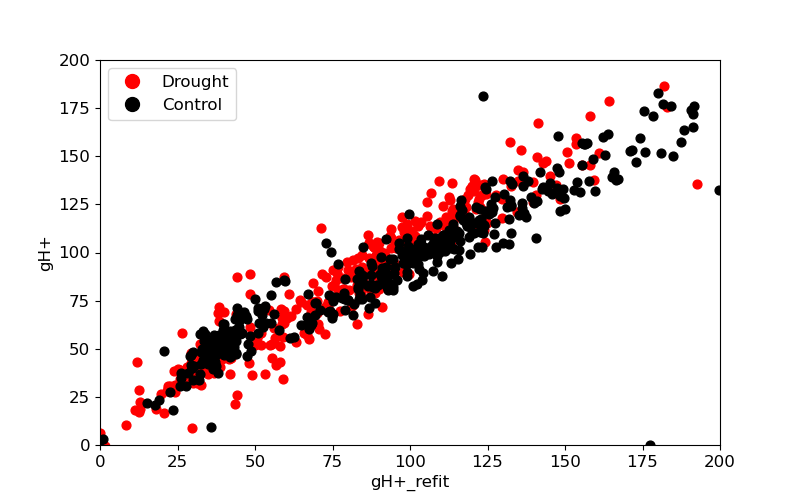

In [8]:
#Comparison of old DIRK data and newly fitted DIRK parameters

plt.figure(figsize=(8,5))
plt.scatter(MSdata_1['ECSt_calc'], MSdata_1['ECSt mAU'], color='red', marker='o', s=80, label='Drought')
plt.scatter(MSdata_0['ECSt_calc'], MSdata_0['ECSt mAU'], color='black', marker='o', s=80, label='Control')
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.ylabel('ECSt mAU', fontsize=12)
plt.xlabel('ECSt_calc', fontsize=12)
legend_elements = [
    Line2D([0], [0], marker='o', color='red', lw=0, label='Drought', markerfacecolor='red', markersize=10),
    Line2D([0], [0], marker='o', color='black', lw=0, label='Control', markerfacecolor='black', markersize=10)
]
plt.legend(handles=legend_elements, loc='upper left', fontsize=12)
plt.xlim(0, 0.005)
plt.ylim(0, 0.005)
plt.show()

plt.figure(figsize=(8,5))
plt.scatter(MSdata_1['gH+_refit'], MSdata_1['gH+'], color='red', marker='o', s=40, label='Drought')
plt.scatter(MSdata_0['gH+_refit'], MSdata_0['gH+'], color='black', marker='o', s=40, label='Control')
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.ylabel('gH+', fontsize=12)
plt.xlabel('gH+_refit', fontsize=12)
legend_elements = [
    Line2D([0], [0], marker='o', color='red', lw=0, label='Drought', markerfacecolor='red', markersize=10),
    Line2D([0], [0], marker='o', color='black', lw=0, label='Control', markerfacecolor='black', markersize=10)
]
plt.legend(handles=legend_elements, loc='upper left', fontsize=12)
plt.xlim(0, 200)
plt.ylim(0, 200)
plt.show()

## Generation of figures with Kernel Density Estimation plot

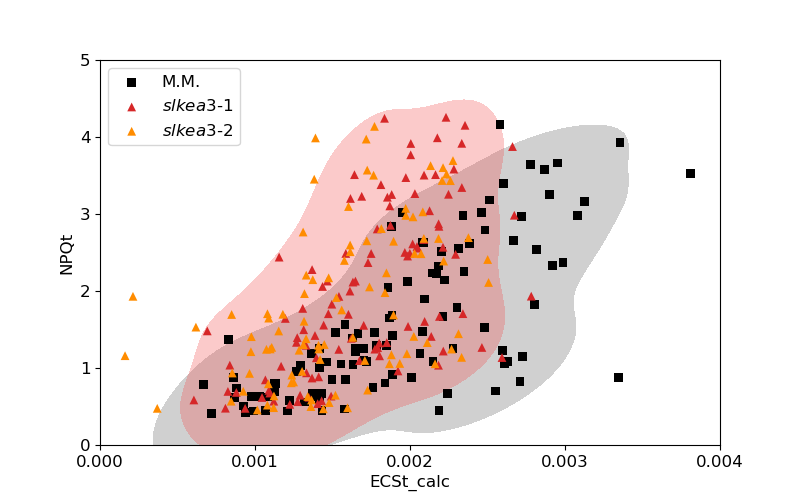

In [9]:
fig = plt.figure(figsize=(8,5))

# Exclude all data where 'Light Intensity (PAR)' is 0, as this data was generated on a different day
MSdata_0_nonzero = MSdata_0[MSdata_0['Light Intensity (PAR)'] != 0]

# Filtering of data: ECSt_calc >= 0, ECSt_calc <= 0.004, 0 <= NPQt <= 6
mask_p1 = (MSdata_0_nonzero['Which plant?'] == 'p1') & (MSdata_0_nonzero['ECSt_calc'] >= 0) & (MSdata_0_nonzero['ECSt_calc'] <= 0.004) & (MSdata_0_nonzero['NPQt'] >= 0) & (MSdata_0_nonzero['NPQt'] <= 6)
mask_p2 = (MSdata_0_nonzero['Which plant?'] == 'p2') & (MSdata_0_nonzero['ECSt_calc'] >= 0) & (MSdata_0_nonzero['ECSt_calc'] <= 0.004) & (MSdata_0_nonzero['NPQt'] >= 0) & (MSdata_0_nonzero['NPQt'] <= 6)
mask_W  = (MSdata_0_nonzero['Which plant?'] == 'W')  & (MSdata_0_nonzero['ECSt_calc'] >= 0) & (MSdata_0_nonzero['ECSt_calc'] <= 0.004) & (MSdata_0_nonzero['NPQt'] >= 0) & (MSdata_0_nonzero['NPQt'] <= 6)

W_x = MSdata_0_nonzero.loc[mask_W, 'ECSt_calc']
W_y = MSdata_0_nonzero.loc[mask_W, 'NPQt']
p_x = MSdata_0_nonzero.loc[mask_p1 | mask_p2, 'ECSt_calc']
p_y = MSdata_0_nonzero.loc[mask_p1 | mask_p2, 'NPQt']

# KDE plots for WT and both mutants together, shaded when the density is >10% of max density of the data
if len(W_x) > 1 and len(W_y) > 1:
    sns.kdeplot(
        x=W_x, y=W_y,
        levels=[0.1, 1], 
        color='grey',
        alpha=0.4,
        fill=True,
        label='W density'
    )

if len(p_x) > 1 and len(p_y) > 1:
    sns.kdeplot(
        x=p_x, y=p_y,
        levels=[0.1, 1], 
        color='tab:red',
        alpha=0.3,
        fill=True,
        label='p1+p2 density'
    )


plt.scatter(W_x, W_y, color='black', marker='s', s=40, label='M.M.', edgecolors='none')
plt.scatter(MSdata_0_nonzero.loc[mask_p1, 'ECSt_calc'], MSdata_0_nonzero.loc[mask_p1, 'NPQt'],
            color='tab:red', marker='^', s=40, label=r'$\it{slkea3\text{-}1}$', edgecolors='none')
plt.scatter(MSdata_0_nonzero.loc[mask_p2, 'ECSt_calc'], MSdata_0_nonzero.loc[mask_p2, 'NPQt'],
            color='darkorange', marker='^', s=40, label=r'$\it{slkea3\text{-}2}$', edgecolors='none')

plt.xlabel('ECSt_calc', fontsize=12)
plt.ylabel('NPQt', fontsize=12)
plt.ylim(0, 5)
plt.xlim(0, 0.004)
plt.xticks(np.arange(0, 0.0041, 0.001), fontsize=12)  
plt.yticks(fontsize=12)
plt.legend(fontsize=12)
plt.show()

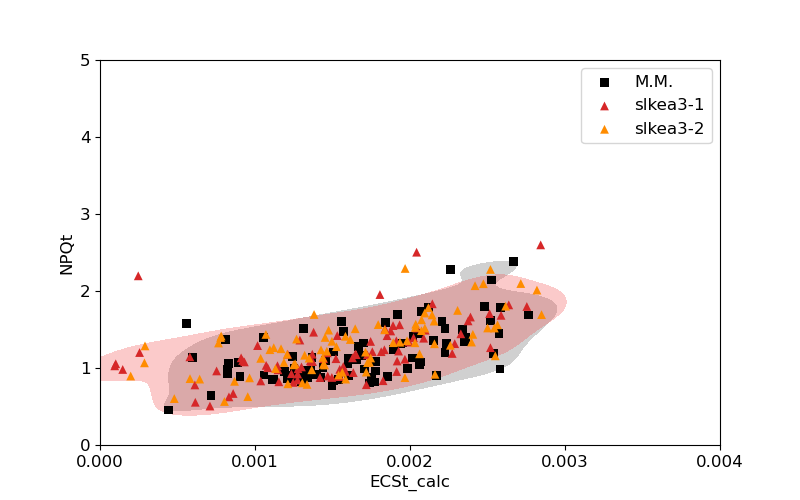

In [10]:
fig = plt.figure(figsize=(8,5))

# Exclude all data where 'Light Intensity (PAR)' is 0, as this data was generated on a different day
MSdata_1_nonzero = MSdata_1[MSdata_1['Light Intensity (PAR)'] != 0]

# Filtering of data: ECSt_calc >= 0, ECSt_calc <= 0.004, 0 <= NPQt <= 6
mask_p1 = (MSdata_1_nonzero['Which plant?'] == 'p1') & (MSdata_1_nonzero['ECSt_calc'] >= 0) & (MSdata_1_nonzero['ECSt_calc'] <= 0.004) & (MSdata_1_nonzero['NPQt'] >= 0) & (MSdata_1_nonzero['NPQt'] <= 6)
mask_p2 = (MSdata_1_nonzero['Which plant?'] == 'p2') & (MSdata_1_nonzero['ECSt_calc'] >= 0) & (MSdata_1_nonzero['ECSt_calc'] <= 0.004) & (MSdata_1_nonzero['NPQt'] >= 0) & (MSdata_1_nonzero['NPQt'] <= 6)
mask_W  = (MSdata_1_nonzero['Which plant?'] == 'W')  & (MSdata_1_nonzero['ECSt_calc'] >= 0) & (MSdata_1_nonzero['ECSt_calc'] <= 0.004) & (MSdata_1_nonzero['NPQt'] >= 0) & (MSdata_1_nonzero['NPQt'] <= 6)

W_x = MSdata_1_nonzero.loc[mask_W, 'ECSt_calc']
W_y = MSdata_1_nonzero.loc[mask_W, 'NPQt']
p_x = MSdata_1_nonzero.loc[mask_p1 | mask_p2, 'ECSt_calc']
p_y = MSdata_1_nonzero.loc[mask_p1 | mask_p2, 'NPQt']

# KDE plots for WT and both mutants together, shaded when the density is >10% of max density of the data
if len(W_x) > 1 and len(W_y) > 1:
    sns.kdeplot(
        x=W_x, y=W_y,
        levels=[0.1, 1],
        color='grey',
        alpha=0.4,
        fill=True,
        label='W density'
    )

if len(p_x) > 1 and len(p_y) > 1:
    sns.kdeplot(
        x=p_x, y=p_y,
        levels=[0.1, 1], 
        color='tab:red',
        alpha=0.3,
        fill=True,
        label='p1+p2 density'
    )

plt.scatter(W_x, W_y, color='black', marker='s', s=40, label='M.M.', edgecolors='none')
plt.scatter(MSdata_1_nonzero.loc[mask_p1, 'ECSt_calc'], MSdata_1_nonzero.loc[mask_p1, 'NPQt'],
            color='tab:red', marker='^', s=40, label='slkea3-1', edgecolors='none')
plt.scatter(MSdata_1_nonzero.loc[mask_p2, 'ECSt_calc'], MSdata_1_nonzero.loc[mask_p2, 'NPQt'],
            color='darkorange', marker='^', s=40, label='slkea3-2', edgecolors='none')

plt.xlabel('ECSt_calc', fontsize=12)
plt.ylabel('NPQt', fontsize=12)
plt.ylim(0, 5)
plt.xlim(0, 0.004)
plt.xticks(np.arange(0, 0.0041, 0.001), fontsize=12)  
plt.yticks(fontsize=12)
plt.legend(fontsize=12)
plt.show()

In [11]:
def count_replicates(df, label):
    df_nonzero = df[df['Light Intensity (PAR)'] != 0]
    print(f"--- {label} ---")
    for plant, name in [('W', 'WT'), ('p1', 'slkea3-1'), ('p2', 'slkea3-2')]:
        mask = (
            (df_nonzero['Which plant?'] == plant) &
            (df_nonzero['ECSt_calc'] >= 0) & (df_nonzero['ECSt_calc'] <= 0.004) &
            (df_nonzero['NPQt'] >= 0) & (df_nonzero['NPQt'] <= 5)
        )
        print(f"{name}: {mask.sum()}")

count_replicates(MSdata_0, 'Control')
count_replicates(MSdata_1, 'Drought')


--- Control ---
WT: 106
slkea3-1: 103
slkea3-2: 97
--- Drought ---
WT: 86
slkea3-1: 87
slkea3-2: 86
